In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [3]:
# STEP 2: LOAD THE NEW CSV DATASET
import pandas as pd
import numpy as np
import os

# Define paths based on your folder structure
csv_path = 'dataset/training.csv'
images_dir = 'dataset/images'

# Load CSV file
df = pd.read_csv(csv_path)
print("📊 CSV Columns found:", list(df.columns)[:5], "...and more!")
print(f"Total rows in dataset: {len(df)}")

# Drop any rows that have missing values so we ONLY train on perfect, complete faces
df_clean = df.dropna()
print(f"Rows with 100% complete landmark columns: {len(df_clean)}")

📊 CSV Columns found: ['left_eye_center_x', 'left_eye_center_y', 'right_eye_center_x', 'right_eye_center_y', 'left_eye_inner_corner_x'] ...and more!
Total rows in dataset: 7049
Rows with 100% complete landmark columns: 2140


In [4]:
# STEP 3: HANDLE MISSING VALUES

df.fillna(df.mean(), inplace=True)

print(df.isnull().sum().sum())

0


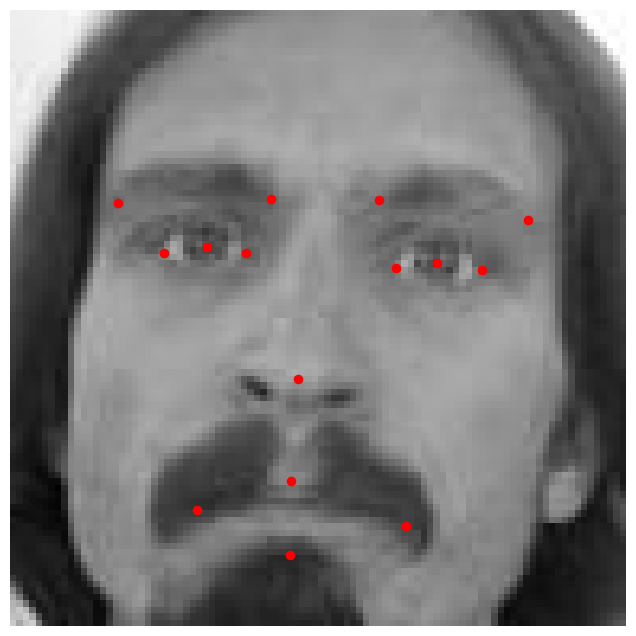

In [13]:
# STEP 4: VISUALIZE LANDMARKS

import os

all_images = os.listdir('dataset/images/train_images')
first_image_name = all_images[0]  # Grabs whatever is first (e.g., "0.jpg", "img_1.png")

# 2. Load that specific file cleanly
img = cv2.imread(f'dataset/images/train_images/{first_image_name}')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 3. Match it to row 0 in your data table
image_id = 0

plt.figure(figsize=(8,8))
plt.imshow(img)

for i in range(0,30,2):
    x = df.iloc[image_id, i]
    y = df.iloc[image_id, i+1]
    plt.scatter(x, y, c='red', s=35)

plt.axis('off')
plt.show()

In [23]:
# STEP 5: PREPROCESS IMAGES (COLOR) AND LABELS FROM CSV
import cv2
import numpy as np
import os

X_list = []
y_list = []

# Target size for the neural network input
IMG_SIZE = 96 

print("⏳ Processing images in full color... Please wait.")

# Loop through every row in our clean dataset
for idx in range(len(df_clean)):
    # 1. Grab the image name dynamically from your directory folder
    all_images = os.listdir('dataset/images/train_images')
    image_name = all_images[idx] 
    img_path = f'dataset/images/train_images/{image_name}'
    
    # 2. Read the image in full color (keeps 3 channels: BGR)
    img = cv2.imread(img_path)
    if img is None:
        continue # Skip any broken images safely
        
    # Convert from BGR (OpenCV default) to RGB so colors display correctly later
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    orig_h, orig_w, _ = img.shape
    
    # 3. Resize image to 96x96
    img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    
    # 4. Extract all 30 coordinate columns for this row
    labels = df_clean.iloc[idx].values[:30].astype('float32')
    
    # 5. Scale coordinates to fit the new 96x96 window size
    for i in range(0, 30, 2):
        labels[i] = (labels[i] / orig_w) * IMG_SIZE     # Scale X coordinate
        labels[i+1] = (labels[i+1] / orig_h) * IMG_SIZE # Scale Y coordinate
        
    X_list.append(img_resized)
    y_list.append(labels)

# Convert lists to final numpy arrays for training
X = np.array(X_list, dtype='float32') / 255.0  # Normalize pixels between 0 and 1
y = np.array(y_list, dtype='float32')

print("✅ Done!")
print(f"Final X Shape (Color Images): {X.shape}")
print(f"Final y Shape (Landmarks): {y.shape}")

⏳ Processing images in full color... Please wait.
✅ Done!
Final X Shape (Color Images): (2140, 96, 96, 3)
Final y Shape (Landmarks): (2140, 30)


In [24]:
# STEP 6: SPLIT DATASET

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_val.shape)

(1712, 96, 96, 3)
(428, 96, 96, 3)


In [25]:
# STEP 7: BUILD CNN MODEL

model = Sequential([

    Input(shape=(96,96,3)),

    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128,(3,3),activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(512,activation='relu'),

    Dense(30)

])

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 94, 94, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 47, 47, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 45, 45, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 22, 22, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 20, 20, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 10, 10, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 12800)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 512)                 │       6,554,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │          15,390 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,662,750 (25.42 MB)

 Trainable params: 6,662,750 (25.42 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# STEP 8: TRAIN MODEL

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val,y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step - loss: 347.0517 - mae: 12.8441 - val_loss: 57.5960 - val_mae: 5.7855
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 110ms/step - loss: 38.4438 - mae: 4.5626 - val_loss: 19.6482 - val_mae: 3.3403
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 105ms/step - loss: 18.7863 - mae: 3.2724 - val_loss: 13.7811 - val_mae: 2.7787
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 121ms/step - loss: 13.5805 - mae: 2.7595 - val_loss: 14.7352 - val_mae: 2.9369
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 146ms/step - loss: 14.9556 - mae: 2.9194 - val_loss: 13.5214 - val_mae: 2.7421
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 139ms/step - loss: 12.6324 - mae: 2.6531 - val_loss: 10.3026 - val_mae: 2.3617
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 137ms/step - loss: 12.0640 - mae: 2.5765 - val_loss: 10.8131 - val_mae: 2.4317
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 133ms/step - loss: 11.4436 - mae: 2.4976 - val_loss: 10.4581 - val_mae: 2.3989
Epoch 9/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 

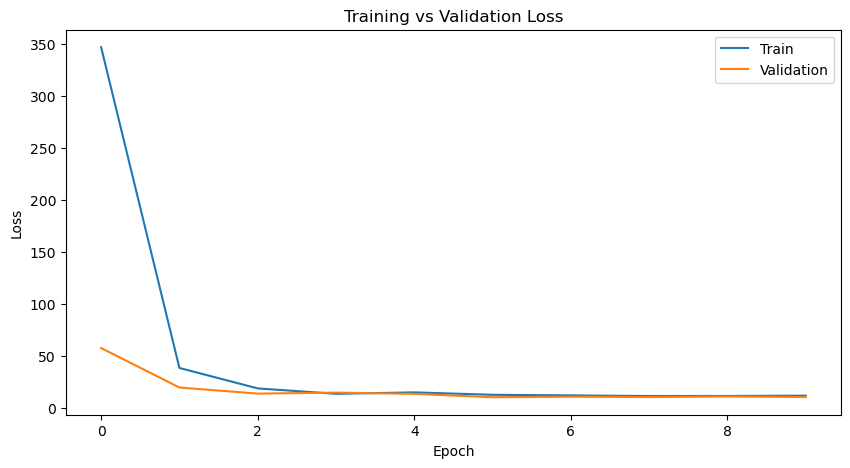

In [27]:
# STEP 9: PLOT LOSS GRAPH

plt.figure(figsize=(10,5))

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend(['Train','Validation'])

plt.show()

In [29]:
# STEP 10: SAVE MODEL

model.save("landmark_detection_model.keras")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step


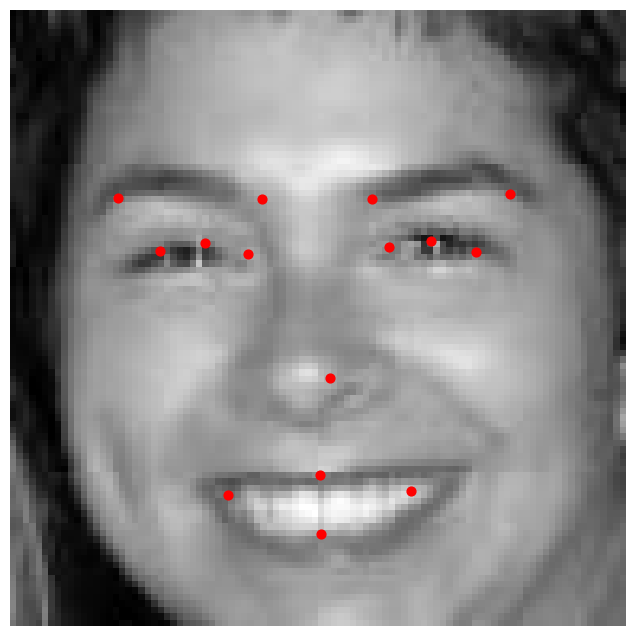

In [31]:
sample = X_val[0]   # Try 100, 500, 1000, etc.

prediction = model.predict(
    np.expand_dims(sample, axis=0)
)

prediction = prediction.reshape(15,2)

plt.figure(figsize=(8,8))
plt.imshow(sample)

for x,y in prediction:
    plt.scatter(x,y,c='red',s=40)

plt.axis('off')
plt.show()

In [3]:
!pip install "numpy<2" "scikit-learn" "tensorflow" --force-reinstall --user

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached scikit_learn-1.9.0-cp312-cp312-win_amd64.whl.metadata (11 kB)
  Using cached tensorflow-2.21.0-cp312-cp312-win_amd64.whl.metadata (4.5 kB)
  Using cached scipy-1.18.0-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached narwhals-2.22.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
  Using cached absl_py-2.4.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached packag

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
aiobotocore 2